# 01. Auditar los datos: ¿cuál es una observación del problema?

**Pregunta central:** ¿qué contiene el paquete y cómo podemos relacionar sus fuentes
sin confundir observaciones satelitales con parcelas que tienen un rendimiento conocido?

**Etapas CRISP-DM:** entender el problema y entender los datos.
**Modo:** recalcular comprobaciones descriptivas; **no se entrena ningún modelo**,
no se extraen valores de los rásteres y no se generan las 59 predicciones finales.

Partimos del ZIP original y comprobamos identidad, unidades, fechas, cobertura y
calidad. Cada salida sustenta una decisión o identifica algo que todavía no demuestra.

- Trabajo original de auditoría: 15 de septiembre de 2026; consolidación: 16 de septiembre.
- Adaptación a este cuaderno autocontenido: 7 de octubre de 2026.
- Revisión de compatibilidad con Python 3.13 y acceso autorizado desde Drive:
  7 de octubre de 2026; no cambia las operaciones de la auditoría.
- La fecha de una nueva ejecución se imprime al iniciar. Esta adaptación no constituye
  un registro previo a la llegada de los datos.

## 1. Preparar una ejecución explícita

**Qué comprobamos.** Que el entorno y el archivo sean identificables.
**Por qué importa.** Leer las salidas guardadas no requiere instalar nada; recalcularlas
requiere las bibliotecas y el mismo paquete original.

**Local:** abrir este cuaderno en el entorno uv del proyecto con los grupos
`notebooks` y `geo`. **Colab:** usar Python **3.13**; el bloque de acceso permite
descargar el ZIP original autorizado desde Drive si no hay una copia local. No hace
falta Git. El cuaderno no sube datos, no publica archivos y no cambia permisos.

**Antes de ejecutar:** `PREPARAR_COLAB = True` permite preparar las bibliotecas
necesarias **solo dentro de Colab**. Primero imprime el plan; instala únicamente
paquetes requeridos cuya versión falta o difiere, con ruedas binarias y dependencias
limitadas por el perfil exportado de uv. En local no instala nada.

Si cambia una biblioteca ya cargada, se detiene y pide reiniciar la sesión y volver
a ejecutar todas las celdas; no mata ni reinicia automáticamente el entorno.
Las comprobaciones cubren las bibliotecas de este cuaderno, no todos los paquetes
preinstalados en Colab. Numba, por ejemplo, no se utiliza ni se actualiza.

La celda técnica siguiente contiene el soporte de preparación y descarga para
que el cuaderno sea autocontenido; puede mantenerse contraída durante la lectura.

In [1]:
"""Preparación explícita de Colab y descarga verificada, sin cambiar cálculos científicos.

Este módulo usa la biblioteca estándar hasta que se solicita preparar Colab o descargar
el ZIP. Se incrusta completo en el notebook para no depender de un clon del proyecto.
"""

from __future__ import annotations

import hashlib
import importlib
import importlib.metadata as metadata
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path


REQUERIDOS_AUDITORIA = (
    "numpy", "pandas", "matplotlib", "pyshp", "shapely", "pyproj", "gdown",
)
MODULOS_DISTRIBUCIONES = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "pyshp": "shapefile", "shapely": "shapely", "pyproj": "pyproj", "gdown": "gdown",
    "pillow": "PIL", "python-dateutil": "dateutil", "beautifulsoup4": "bs4",
    "scikit-learn": "sklearn", "pysocks": "socks", "typing-extensions": "typing_extensions",
}


class ReinicioColabRequerido(RuntimeError):
    """Una instalación cambió una biblioteca que ya estaba cargada en la sesión."""

    def __init__(self, cambios: list[str], modulos_cargados: list[str]):
        self.cambios = cambios
        self.modulos_cargados = modulos_cargados
        super().__init__(
            "Las versiones se prepararon, pero ya había módulos cargados que cambiaron: "
            + ", ".join(modulos_cargados)
            + ". En Colab selecciona Entorno de ejecución > Reiniciar sesión y después "
            "Ejecutar todas. No se reinicia ni se mata la sesión automáticamente."
        )


def _perfil_fijado(perfil: str) -> dict[str, str]:
    versiones = {}
    for nombre, version in re.findall(
        r"^([A-Za-z0-9_-]+)==([^\s;]+)", perfil, flags=re.MULTILINE,
    ):
        clave = nombre.lower().replace("_", "-")
        if clave in versiones:
            raise ValueError(f"Paquete repetido en el perfil: {nombre}")
        versiones[clave] = version
    if not versiones:
        raise ValueError("El perfil de uv no contiene versiones fijadas.")
    return versiones


def versiones_requeridas(
    perfil: str, nombres: tuple[str, ...] = REQUERIDOS_AUDITORIA,
) -> dict[str, str]:
    """Lee las versiones de las raíces realmente utilizadas en esta auditoría."""
    fijadas = _perfil_fijado(perfil)
    faltantes = [nombre for nombre in nombres if nombre not in fijadas]
    if faltantes:
        raise ValueError("Faltan paquetes del cuaderno en el perfil uv: " + ", ".join(faltantes))
    return {nombre: fijadas[nombre] for nombre in nombres}


def _version_o_ausente(nombre: str, consultar_version) -> str | None:
    try:
        return consultar_version(nombre)
    except metadata.PackageNotFoundError:
        return None


def _modulo_cargado(nombre: str, modulos) -> bool:
    raiz = MODULOS_DISTRIBUCIONES.get(nombre, nombre.replace("-", "_"))
    return any(clave == raiz or clave.startswith(raiz + ".") for clave in modulos)


def _comprobar_importaciones(versiones: dict[str, str]) -> None:
    """Prueba importaciones y operaciones pequeñas; no entrena ni lee datos del reto."""
    for nombre, esperada in versiones.items():
        modulo = importlib.import_module(MODULOS_DISTRIBUCIONES.get(nombre, nombre))
        version_cargada = getattr(modulo, "__version__", None)
        if version_cargada is not None and str(version_cargada) != esperada:
            raise ReinicioColabRequerido([], [nombre])
    import numpy as np
    import pandas as pd
    from pyproj import Transformer
    from shapely.geometry import Point

    if not np.isclose(np.array([1.0, 3.0]).mean(), 2.0):
        raise RuntimeError("No pasó la comprobación mínima de NumPy.")
    if pd.DataFrame({"x": [1, 2]}).shape != (2, 1):
        raise RuntimeError("No pasó la comprobación mínima de pandas.")
    if Point(0, 0).is_empty:
        raise RuntimeError("No pasó la comprobación mínima de Shapely.")
    x, y = Transformer.from_crs(4326, 3857, always_xy=True).transform(0, 0)
    if not np.allclose([x, y], [0, 0]):
        raise RuntimeError("No pasó la comprobación mínima de PROJ.")


def _avisar_incompatibilidad_numba(informar) -> None:
    """Aviso acotado: este notebook no usa ni modifica Numba."""
    try:
        requisitos = metadata.requires("numba") or []
        from packaging.requirements import Requirement

        numpy_version = metadata.version("numpy")
        for texto in requisitos:
            requisito = Requirement(texto)
            if requisito.name.lower() != "numpy":
                continue
            if requisito.marker is not None and not requisito.marker.evaluate():
                continue
            if numpy_version not in requisito.specifier:
                informar(
                    f"Aviso del entorno de Colab: Numba declara {requisito}, pero NumPy es "
                    f"{numpy_version}. Este cuaderno no usa Numba ni lo actualiza. "
                    "La verificación cubre sus bibliotecas, no todos los paquetes de Colab."
                )
    except (metadata.PackageNotFoundError, ImportError):
        return


def preparar_colab(
    perfil: str, *, en_colab: bool, habilitar: bool = True,
    consultar_version=metadata.version, modulos=None, ejecutar=subprocess.check_call,
    informar=print, verificar_importaciones=None,
) -> dict:
    """Instala solo raíces distintas/faltantes en Colab, con dependencias restringidas por uv.

    Las funciones inyectables permiten probar instalación, versiones y reinicio sin red.
    En local no se llama a pip ni se modifica el entorno: lo prepara uv.
    """
    esperadas = versiones_requeridas(perfil)
    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    cambios = [f"{nombre}=={version}" for nombre, version in esperadas.items()
               if instaladas[nombre] != version]
    if not en_colab:
        informar("Entorno local: no se instala nada desde el cuaderno; se utiliza uv.")
        return {"estado": "local_sin_instalar", "cambios": [], "instaladas": instaladas,
                "reinicio_requerido": False}

    informar("Preparación de Colab: Python y paquetes se comprobarán antes de leer datos.")
    informar("Plan: " + (", ".join(cambios) if cambios else "sin instalaciones necesarias"))
    if cambios and not habilitar:
        raise RuntimeError(
            "El perfil difiere y PREPARAR_COLAB está desactivado. Actívalo y vuelve "
            "a ejecutar esta celda, o prepara manualmente las versiones impresas."
        )

    fijadas = _perfil_fijado(perfil)
    modulos = sys.modules if modulos is None else modulos
    cargados_antes = {nombre for nombre in fijadas if _modulo_cargado(nombre, modulos)}
    versiones_antes = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in cargados_antes
    }
    if cambios:
        with tempfile.TemporaryDirectory(prefix="agrocebada-colab-perfil-") as carpeta:
            restricciones = Path(carpeta) / "perfil-uv-constraints.txt"
            restricciones.write_text(perfil, encoding="utf-8")
            comando = [sys.executable, "-m", "pip", "install", "--only-binary=:all:",
                       "--disable-pip-version-check", "--constraint", str(restricciones),
                       *cambios]
            informar("Se instala únicamente el plan; dependencias necesarias limitadas por uv.")
            try:
                ejecutar(comando)
            except (subprocess.CalledProcessError, OSError) as error:
                raise RuntimeError(
                    "No se pudo preparar el perfil binario. No se ejecutará la auditoría "
                    "con otras versiones. Revisa el error de pip y reinicia la sesión "
                    "si la instalación quedó a medias."
                ) from error

        importlib.invalidate_caches()
        cargados_cambiados = sorted(
            nombre for nombre in cargados_antes
            if versiones_antes[nombre] != _version_o_ausente(nombre, consultar_version)
            or any(cambio.startswith(nombre + "==") for cambio in cambios)
        )
        if cargados_cambiados:
            raise ReinicioColabRequerido(cambios, cargados_cambiados)

    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    divergentes = [nombre for nombre, version in esperadas.items()
                  if instaladas[nombre] != version]
    if divergentes:
        raise RuntimeError("El perfil no coincide tras prepararlo: " + ", ".join(divergentes))
    comprobar = _comprobar_importaciones if verificar_importaciones is None else (
        verificar_importaciones
    )
    comprobar(esperadas)
    # Evita inspeccionar el entorno verdadero en pruebas con proveedores de versiones inventados.
    if consultar_version is metadata.version:
        _avisar_incompatibilidad_numba(informar)
    informar("Perfil requerido e importaciones comprobados; no se garantiza todo el entorno Colab.")
    return {"estado": "colab_instalado" if cambios else "colab_existente", "cambios": cambios,
            "instaladas": instaladas, "reinicio_requerido": False}


def validar_dataset(ruta: Path, sha256_esperado: str, bytes_esperados: int) -> Path:
    """Rechaza tamaño o huella incorrectos antes de que se abra el ZIP."""
    ruta = Path(ruta)
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo de entrada: {ruta}")
    if ruta.stat().st_size != bytes_esperados:
        raise ValueError(f"Tamaño incorrecto de {ruta.name}: se esperaban {bytes_esperados} bytes.")
    huella = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)
    if huella.hexdigest() != sha256_esperado:
        raise ValueError(f"SHA-256 incorrecto de {ruta.name}; no se usará este archivo.")
    return ruta


def obtener_dataset(
    destino: Path, *, file_id: str | None = None, sha256_esperado: str,
    bytes_esperados: int, permitir_descarga: bool, descargar=None,
) -> Path:
    """Usa caché validada o descarga explícita a temporal; publica solo bytes verificados.

    Una copia local incorrecta nunca se sustituye silenciosamente. Una descarga rechazada
    queda en cuarentena para diagnóstico; no se cambian permisos, cuentas ni credenciales.
    """
    destino = Path(destino).expanduser()
    if destino.exists():
        return validar_dataset(destino, sha256_esperado, bytes_esperados)
    if not permitir_descarga:
        raise FileNotFoundError(
            "No está el ZIP original. En local, coloca DataSet.zip en data/raw/ o indica "
            "RUTA_DATASET. La descarga solo se habilita explícitamente."
        )
    if file_id is None or not re.fullmatch(r"[A-Za-z0-9_-]{10,}", file_id):
        raise ValueError(
            "Falta el ID de Drive del ZIP original autorizado. Configura ID_DRIVE_DATASET "
            "(no el ID del notebook), o proporciona una copia local verificada."
        )
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    destino.parent.mkdir(parents=True, exist_ok=True)
    descriptor, nombre_temporal = tempfile.mkstemp(
        prefix=destino.name + ".", suffix=".part", dir=destino.parent,
    )
    os.close(descriptor)
    temporal = Path(nombre_temporal)
    try:
        if descargar is None:
            import gdown

            descargar = gdown.download
        resultado = descargar(
            id=file_id, output=str(temporal), quiet=False, use_cookies=False,
        )
        if resultado is None:
            raise RuntimeError("Drive no entregó un archivo descargable.")
        validar_dataset(temporal, sha256_esperado, bytes_esperados)
        # Mismo directorio/sistema de archivos: la creación del enlace publica el
        # archivo completo y falla atómicamente si otra ejecución ganó la carrera.
        # No usamos exists() + replace(), que permitiría sustituir una aparición
        # concurrente entre ambas operaciones.
        try:
            os.link(temporal, destino)
        except FileExistsError:
            validar_dataset(destino, sha256_esperado, bytes_esperados)
        except OSError as error:
            raise RuntimeError(
                "Este destino no permite publicar mediante enlace atómico sin reemplazo. "
                "Usa una carpeta local de la sesión; no se sobrescribirá otro archivo."
            ) from error
        temporal.unlink()
        return destino
    except Exception as error:
        if temporal.exists():
            cuarentena = temporal.with_suffix(".rechazado")
            os.replace(temporal, cuarentena)
            detalle = f" Archivo recibido conservado para revisión en {cuarentena.name}."
        else:
            detalle = ""
        raise RuntimeError(
            "La descarga no quedó publicada como DataSet.zip: comprueba enlace, permisos, "
            "cuota y coincidencia de tamaño/SHA-256." + detalle
        ) from error


In [2]:
# Acción visible: prepara paquetes SOLO dentro de Colab; uv se ocupa del entorno local.
PREPARAR_COLAB = True
import importlib.util
import sys
from pathlib import Path

try:
    EN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    EN_COLAB = False

if sys.version_info[:2] != (3, 13):
    raise RuntimeError("Local y Colab requieren Python 3.13; no se instala otro perfil.")

# Perfil completo exportado de uv.lock; incluye dependencias transitivas.
REQUIREMENTS_COLAB = "affine==3.0.1\n    # via rasterio\nattrs==26.1.0\n    # via\n    #   affine\n    #   rasterio\nbeautifulsoup4==4.15.0\n    # via gdown\ncertifi==2026.7.22\n    # via\n    #   pyproj\n    #   rasterio\n    #   requests\ncharset-normalizer==3.5.2\n    # via requests\nclick==8.5.0\n    # via rasterio\ncloudpickle==3.1.2\n    # via joblib\ncolorama==0.4.6 ; sys_platform == 'win32'\n    # via tqdm\ncontourpy==1.4.0\n    # via matplotlib\ncycler==0.12.1\n    # via matplotlib\nfilelock==4.0.12\n    # via gdown\nfonttools==4.66.1\n    # via matplotlib\ngdown==5.2.2\nidna==3.20\n    # via requests\njoblib==1.6.0\n    # via scikit-learn\nkiwisolver==1.5.1\n    # via matplotlib\nmatplotlib==3.11.2\nnarwhals==2.26.0\n    # via scikit-learn\nnumpy==2.4.4\n    # via\n    #   agrocebada-uv\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   rasterio\n    #   scikit-learn\n    #   scipy\n    #   shapely\npackaging==26.3\n    # via matplotlib\npandas==2.2.3\n    # via agrocebada-uv\npillow==12.3.0\n    # via matplotlib\npyparsing==3.3.3\n    # via\n    #   matplotlib\n    #   rasterio\npyproj==3.8.0\npyshp==3.1.6\npysocks==1.7.1\n    # via requests\npython-dateutil==2.9.0.post0\n    # via\n    #   matplotlib\n    #   pandas\npytz==2026.5\n    # via pandas\nrasterio==1.5.2\nrequests==2.34.2\n    # via gdown\nscikit-learn==1.9.1\n    # via agrocebada-uv\nscipy==1.18.0\n    # via\n    #   agrocebada-uv\n    #   scikit-learn\nshapely==2.1.2\nsix==1.17.0\n    # via python-dateutil\nsoupsieve==2.10\n    # via beautifulsoup4\nthreadpoolctl==3.7.0\n    # via scikit-learn\ntqdm==4.70.1\n    # via gdown\ntyping-extensions==4.16.0\n    # via beautifulsoup4\ntzdata==2026.5\n    # via pandas\nurllib3==2.8.0\n    # via requests\n"
VERSIONES = {'numpy': '2.4.4', 'pandas': '2.2.3', 'matplotlib': '3.11.2', 'pyshp': '3.1.6', 'shapely': '2.1.2', 'pyproj': '3.8.0', 'gdown': '5.2.2'}
preparacion_entorno = preparar_colab(
    REQUIREMENTS_COLAB, en_colab=EN_COLAB, habilitar=PREPARAR_COLAB,
)
print("Preparación:", preparacion_entorno["estado"])

Entorno local: no se instala nada desde el cuaderno; se utiliza uv.
Preparación: local_sin_instalar


In [3]:
import hashlib
import importlib.metadata as metadata
import io
import json
import platform
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Polygon as ParchePoligono
from pyproj import Transformer
from shapely.ops import transform

tabla_entorno = pd.DataFrame([
    {"biblioteca": nombre, "esperada": esperada,
     "instalada": metadata.version(nombre)}
    for nombre, esperada in VERSIONES.items()
])
FECHA_EJECUCION_UTC = datetime.now(timezone.utc).isoformat()
print("Python:", platform.python_version())
print("Ejecución UTC:", FECHA_EJECUCION_UTC)
print("Superficie:", "Colab" if EN_COLAB else "entorno local")
display(tabla_entorno)
assert sys.version_info[:2] == (3, 13), "El proyecto y Colab utilizan Python 3.13."
assert tabla_entorno["esperada"].eq(tabla_entorno["instalada"]).all(), (
    "Las versiones difieren. Prepara el perfil uv o usa la instalación explícita de Colab."
)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

Python: 3.13.13
Ejecución UTC: 2026-10-07T18:42:37.295074+00:00
Superficie: entorno local


,biblioteca,esperada,instalada
0,numpy,2.4.4,2.4.4
1,pandas,2.2.3,2.2.3
2,matplotlib,3.11.2,3.11.2
3,pyshp,3.1.6,3.1.6
4,shapely,2.1.2,2.1.2
5,pyproj,3.8.0,3.8.0
6,gdown,5.2.2,5.2.2


**Celda técnica del lector.** El siguiente bloque contiene completo el código de lectura
y validación, en lugar de importar un módulo de una máquina particular. Se puede
desplegar para revisar los controles; las comprobaciones y sus resultados se presentan
después. No repara polígonos, no rellena faltantes y no cambia los archivos originales.

In [4]:
"""Lectores y controles del cuaderno 01; sin extracción de variables ni modelos.

Se leen los archivos en memoria. Ninguna función modifica o descomprime los
originales en el sistema de archivos. El mismo texto se incrusta en el notebook.
"""

import hashlib
import io
import re
import zipfile
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import shapefile
from pyproj import CRS
from shapely.geometry import shape


SHA256_DATASET = "d74dbaba1764e026da8ce38f7f3476f80523f479a6c141827887e09326061bb5"
MAX_ARCHIVO_BYTES = 256 * 1024 * 1024
MAX_TOTAL_BYTES = 512 * 1024 * 1024
MAX_MIEMBROS = 1000


def validar_zip(z):
    """Rechaza nombres ambiguos/peligrosos y limita bytes antes de leerlos."""
    vistos, inventario = set(), []
    infos = z.infolist()
    if len(infos) > MAX_MIEMBROS:
        raise ValueError("ZIP con demasiados miembros")
    if sum(info.file_size for info in infos) > MAX_TOTAL_BYTES:
        raise ValueError("ZIP excede el límite total de bytes descomprimidos")
    for info in infos:
        nombre = info.filename
        ruta = PurePosixPath(nombre)
        clave = nombre.rstrip("/").casefold()
        if (
            "\\" in nombre or "\x00" in nombre or ruta.is_absolute()
            or ".." in ruta.parts or re.match(r"^[A-Za-z]:", nombre)
            or not ruta.parts or clave in vistos
        ):
            raise ValueError(f"Ruta insegura o duplicada en ZIP: {nombre!r}")
        vistos.add(clave)
        if (info.external_attr >> 16) & 0o170000 == 0o120000:
            raise ValueError(f"Enlace simbólico no admitido: {nombre}")
        if info.file_size > MAX_ARCHIVO_BYTES:
            raise ValueError(f"Miembro excede el límite de bytes: {nombre}")
        if info.flag_bits & 1:
            raise ValueError("ZIP cifrado no admitido en esta auditoría")
    # z.read comprueba CRC; no se escriben rutas del ZIP en disco.
    for info in infos:
        if not info.is_dir():
            contenido = z.read(info)
            inventario.append({
                "nombre": info.filename,
                "bytes": len(contenido),
                "sha256": hashlib.sha256(contenido).hexdigest(),
            })
    return inventario


def cargar_zip(path):
    ruta = Path(path)
    if ruta.stat().st_size > MAX_TOTAL_BYTES:
        raise ValueError("Archivo de entrada demasiado grande")
    contenido = ruta.read_bytes()
    digest = hashlib.sha256(contenido).hexdigest()
    if digest != SHA256_DATASET:
        raise ValueError(f"Dataset incorrecto: SHA-256 {digest}; se detiene la lectura")
    archivo = zipfile.ZipFile(io.BytesIO(contenido))
    validar_zip(archivo)
    return archivo


def miembro_unico(z, terminacion):
    nombres = [i.filename for i in z.infolist()
               if not i.is_dir() and (
                   i.filename.endswith(terminacion) if terminacion.startswith(".")
                   else PurePosixPath(i.filename).name == terminacion
               )]
    if len(nombres) != 1:
        raise ValueError(f"Se esperaba un miembro para {terminacion!r}, hay {len(nombres)}")
    return nombres[0]


def leer_csv(z, terminacion):
    return pd.read_csv(io.BytesIO(z.read(miembro_unico(z, terminacion))), encoding="utf-8-sig")


def normalizar_catalogo(df):
    """Solo elimina separadores vacíos; no imputa, redondea ni cambia etiquetas."""
    copia = df.copy(deep=True)
    vacias = [col for col in copia.columns if str(col).startswith("Unnamed:")]
    if any(copia[col].notna().any() for col in vacias):
        raise ValueError("Una columna sin nombre contiene datos; no se elimina")
    copia = copia.drop(columns=vacias)
    requeridas = ["ID_POLIGONO", "AREA_HA", "RENDIMIENTO_T_HA", "CONJUNTO"]
    if list(copia.columns) != requeridas:
        raise ValueError("Esquema de catálogo inesperado")
    ids = copia.ID_POLIGONO
    if ids.isna().any() or not ids.astype(str).str.fullmatch(r"AGC_\d{3}").all():
        raise ValueError("Identificadores vacíos o mal formados")
    if ids.duplicated().any():
        raise ValueError("Identificador de parcela duplicado")
    if not copia.CONJUNTO.isin(["ENTRENAMIENTO", "PREDICCION"]).all():
        raise ValueError("CONJUNTO desconocido")
    for col in ["AREA_HA", "RENDIMIENTO_T_HA"]:
        copia[col] = pd.to_numeric(copia[col], errors="raise")
    if not np.isfinite(copia.AREA_HA).all() or (copia.AREA_HA <= 0).any():
        raise ValueError("Área no positiva o no finita")
    train = copia.CONJUNTO.eq("ENTRENAMIENTO")
    if copia.loc[train, "RENDIMIENTO_T_HA"].isna().any():
        raise ValueError("Rendimiento ausente en entrenamiento")
    if copia.loc[~train, "RENDIMIENTO_T_HA"].notna().any():
        raise ValueError("Etiqueta visible en PREDICCION")
    y = copia.loc[train, "RENDIMIENTO_T_HA"]
    if not np.isfinite(y).all() or (y <= 0).any():
        raise ValueError("Rendimiento observado no positivo o no finito")
    return copia


def validar_satelite(df):
    copia = df.copy(deep=True)
    requeridas = {"ID_POLIGONO", "fecha_captura", "sensor", "porcentaje_nubosidad"}
    if not requeridas <= set(copia.columns):
        raise ValueError("Columnas satelitales requeridas ausentes")
    if copia[["ID_POLIGONO", "fecha_captura", "sensor"]].isna().any().any():
        raise ValueError("ID, fecha o sensor ausente")
    if not copia.ID_POLIGONO.astype(str).str.fullmatch(r"AGC_\d{3}").all():
        raise ValueError("ID satelital mal formado")
    if copia.sensor.astype(str).str.strip().eq("").any():
        raise ValueError("Sensor vacío")
    if not copia.fecha_captura.astype(str).str.fullmatch(r"\d{2}/\d{2}/\d{4}").all():
        raise ValueError("Fecha satelital no tiene formato dd/mm/aaaa")
    copia["FECHA"] = pd.to_datetime(copia.fecha_captura, format="%d/%m/%Y", errors="raise")
    if copia.duplicated(["ID_POLIGONO", "FECHA", "sensor"]).any():
        raise ValueError("Observación parcela-fecha-sensor duplicada")
    nube = pd.to_numeric(copia.porcentaje_nubosidad, errors="raise")
    presentes = nube.dropna()
    if not np.isfinite(presentes).all() or not presentes.between(0, 100).all():
        raise ValueError("Nubosidad fuera de 0–100 o no finita")
    return copia


def leer_geometrias(z):
    contenido = z.read(miembro_unico(z, "Parcelas_Reto_AGC_CONJUNTO_70_30.zip"))
    with zipfile.ZipFile(io.BytesIO(contenido)) as interno:
        validar_zip(interno)
        lector = shapefile.Reader(
            shp=io.BytesIO(interno.read(miembro_unico(interno, ".shp"))),
            shx=io.BytesIO(interno.read(miembro_unico(interno, ".shx"))),
            dbf=io.BytesIO(interno.read(miembro_unico(interno, ".dbf"))),
            encoding="utf-8", encodingErrors="strict",
        )
        crs = CRS.from_wkt(interno.read(miembro_unico(interno, ".prj")).decode("utf-8"))
        registros = list(lector.iterShapeRecords())
        tabla = pd.DataFrame([r.record.as_dict() for r in registros]).rename(columns={
            "ID_POLIGON": "ID_POLIGONO", "área_ha": "AREA_HA_GEOMETRIA",
            "CONJUNTO": "CONJUNTO_GEOMETRIA",
        })
        geometrias = [shape(r.shape.__geo_interface__) for r in registros]
        lector.close()
    esperadas = {
        "ID_POLIGONO", "AREA_HA_GEOMETRIA", "CONJUNTO_GEOMETRIA", "Estado", "Municipio", "Cultivo",
    }
    if set(tabla.columns) != esperadas or tabla.ID_POLIGONO.duplicated().any():
        raise ValueError("Esquema o identificadores del shapefile inesperados")
    if any(g.is_empty or not g.is_valid or g.geom_type not in {"Polygon", "MultiPolygon"}
           for g in geometrias):
        raise ValueError("Geometría inválida/vacía/no poligonal: se requiere revisión, no reparación")
    if len(tabla) != len(geometrias):
        raise ValueError("Geometrías y atributos no alineados")
    return tabla, geometrias, crs


## 2. Identificar el paquete antes de usarlo

**Qué comprobamos.** Nombre, tamaño, SHA-256, miembros y CRC del ZIP.
**Por qué importa.** Un resultado reproducible debe identificar exactamente qué
versión leyó. Un hash acredita identidad de bytes, no la fecha en que se creó un archivo.

Es el `DataSet.zip` proporcionado para el reto, no una tabla de variables ya procesada.
Si no está en una ubicación sugerida, escribe la ruta en `RUTA_DATASET`. En Colab,
`DESCARGAR_DATASET = True` permite descargar la copia de Drive compartida para el
equipo. El ID debe corresponder al **ZIP**, no al notebook.

La descarga se escribe primero en un archivo temporal; solo se acepta como
`DataSet.zip` tras comprobar tamaño y SHA-256. Una copia existente incorrecta se
rechaza sin sustituirla; una descarga fallida se conserva en cuarentena para revisarla.
Los permisos los concede quien comparte el archivo: este cuaderno no los cambia
ni utiliza credenciales o cookies del navegador.

In [5]:
# Cambia únicamente esta configuración si el archivo está en otra ubicación.
RUTA_DATASET = None  # Ejemplo: Path("/content/DataSet.zip")
ID_DRIVE_DATASET = '1sVcOKLnbU_l7N6RA6RXc_P2zgcnJNOqL'  # ID del ZIP original autorizado, no del notebook.
DESCARGAR_DATASET = EN_COLAB  # En local no se descarga por defecto.
candidatos = [
    Path("data/raw/DataSet.zip"), Path("../data/raw/DataSet.zip"),
    Path("DataSet.zip"), Path("/content/DataSet.zip"),
]
ruta_dataset = (
    Path(RUTA_DATASET).expanduser() if RUTA_DATASET is not None
    else next((ruta for ruta in candidatos if ruta.is_file()), None)
)
if ruta_dataset is None:
    ruta_dataset = Path("/content/DataSet.zip") if EN_COLAB else Path("data/raw/DataSet.zip")
ruta_dataset = obtener_dataset(
    ruta_dataset, file_id=ID_DRIVE_DATASET,
    sha256_esperado=SHA256_DATASET, bytes_esperados=29_687_194,
    permitir_descarga=DESCARGAR_DATASET,
)
hash_inicial = hashlib.sha256(ruta_dataset.read_bytes()).hexdigest()
zip_fuente = cargar_zip(ruta_dataset)
inventario = pd.DataFrame(validar_zip(zip_fuente))
print("Entrada:", ruta_dataset.name)
print("Bytes:", ruta_dataset.stat().st_size)
print("SHA-256:", hash_inicial)
assert hash_inicial == SHA256_DATASET
assert ruta_dataset.stat().st_size == 29_687_194
display(inventario.assign(
    archivo=inventario["nombre"].map(lambda nombre: nombre.rsplit("/", 1)[-1]),
    sha256_corto=inventario["sha256"].str[:16],
)[["archivo", "bytes", "sha256_corto"]])

Entrada: DataSet.zip
Bytes: 29687194
SHA-256: d74dbaba1764e026da8ce38f7f3476f80523f479a6c141827887e09326061bb5


,archivo,bytes,sha256_corto
0,Conjunto_datos_BASICO_AgroCebada2026.csv,33668409,96d68040d954d090
1,Conjunto_datos_PRO_AgroCebada.csv,5000244,91697f8f8d4ad5e5
2,Descripcion_general_variables_DataSet.docx,148153,9fe996d3634eeede
3,Diccionario_de_indices_satelitales.docx,147776,f6b5aed403629534
4,ID_area_rendimiento_70_30_Reto_AgroCebada.csv,6241,ec07b7ede0ae6921
5,Parcelas_Reto_AGC_CONJUNTO_70_30.zip,85593,bb7155e551e1f89f
6,Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025...,483110,f6523158ac78ea30
7,Reto_AgroCebada_Temperatura_2022_2025_RECORTAD...,1339334,3935325c5e7c55e4
8,Reto_AgroCebada_Topografia_INEGI_CEM4.zip,17705629,53434effd80ff575


**Qué significa.** La tabla distingue dos CSV satelitales, un catálogo de rendimientos,
geometrías, cartografía y documentación. Las huellas completas permanecen en
`inventario`; la tabla solo abrevia su visualización.

**No demuestra:** que los datos carezcan de sesgos, ni que las fechas internas del ZIP
sean sellos de tiempo independientes. Integridad y validez científica son cosas distintas.

Ahora abrimos los ZIP internos en memoria para contar sus miembros. No se extraen
valores de los píxeles ni se comparan sus mallas todavía.

In [6]:
componentes = [
    ("Geometrías", "Parcelas_Reto_AGC_CONJUNTO_70_30.zip", 0),
    ("Precipitación", "Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025.zip", 48),
    ("Temperatura", "Reto_AgroCebada_Temperatura_2022_2025_RECORTADA_CHIRPS.zip", 96),
    ("Topografía", "Reto_AgroCebada_Topografia_INEGI_CEM4.zip", 2),
]
filas_componentes = []
for componente, nombre_zip, cantidad_tif in componentes:
    nombre = miembro_unico(zip_fuente, nombre_zip)
    with zipfile.ZipFile(io.BytesIO(zip_fuente.read(nombre))) as interno:
        detalles = validar_zip(interno)
        n_tif = sum(fila["nombre"].lower().endswith((".tif", ".tiff"))
                    for fila in detalles)
        assert n_tif == cantidad_tif, f"Inventario inesperado: {componente}"
        filas_componentes.append({
            "componente": componente, "archivos": len(detalles), "rásteres": n_tif,
            "integridad": "CRC y rutas válidos",
        })
tabla_componentes = pd.DataFrame(filas_componentes)
display(tabla_componentes)

,componente,archivos,rásteres,integridad
0,Geometrías,5,0,CRC y rutas válidos
1,Precipitación,50,48,CRC y rutas válidos
2,Temperatura,98,96,CRC y rutas válidos
3,Topografía,4,2,CRC y rutas válidos


## 3. El objetivo: una etiqueta por parcela

**Qué comprobamos.** El catálogo, sus unidades y la consistencia de los conjuntos.
**Por qué importa.** El objetivo es un número continuo —rendimiento en **t/ha**—:
es regresión supervisada, no clasificación de parcelas.

Conservamos la lectura original en `catalogo_crudo`. La copia de trabajo solo retira
una columna sin nombre si **todos** sus valores están vacíos; nunca la elimina a ciegas.
El lector exige IDs únicos, áreas positivas y etiquetas coherentes con `CONJUNTO`.

In [7]:
catalogo_crudo = leer_csv(zip_fuente, "ID_area_rendimiento_70_30_Reto_AgroCebada.csv")
catalogo = normalizar_catalogo(catalogo_crudo)
columnas_vacias = [columna for columna in catalogo_crudo.columns
                  if columna not in catalogo.columns]
print("Dimensión física del CSV:", catalogo_crudo.shape)
print("Columnas con significado:", list(catalogo.columns))
print("Columna vacía retirada de la copia:", columnas_vacias)
assert catalogo_crudo.shape == (197, 5)
assert catalogo.shape == (197, 4)
muestra = catalogo[["ID_POLIGONO", "AREA_HA", "CONJUNTO"]].head(6).copy()
muestra["etiqueta_disponible"] = catalogo["RENDIMIENTO_T_HA"].notna().head(6)
display(muestra)

Dimensión física del CSV: (197, 5)
Columnas con significado: ['ID_POLIGONO', 'AREA_HA', 'RENDIMIENTO_T_HA', 'CONJUNTO']
Columna vacía retirada de la copia: ['Unnamed: 4']


,ID_POLIGONO,AREA_HA,CONJUNTO,etiqueta_disponible
0,AGC_001,7.61,ENTRENAMIENTO,True
1,AGC_002,2.31,ENTRENAMIENTO,True
2,AGC_003,18.68,PREDICCION,False
3,AGC_004,8.00,ENTRENAMIENTO,True
4,AGC_005,2.27,ENTRENAMIENTO,True
5,AGC_006,3.84,ENTRENAMIENTO,True


In [8]:
tabla_objetivo = catalogo.groupby("CONJUNTO").agg(
    parcelas=("ID_POLIGONO", "nunique"),
    etiquetas_visibles=("RENDIMIENTO_T_HA", "count"),
).reset_index()
tabla_objetivo["etiquetas_ausentes"] = (
    tabla_objetivo["parcelas"] - tabla_objetivo["etiquetas_visibles"]
)
n_parcelas = catalogo["ID_POLIGONO"].nunique()
n_etiquetas = catalogo["RENDIMIENTO_T_HA"].notna().sum()
n_ocultas = catalogo["RENDIMIENTO_T_HA"].isna().sum()
assert (n_parcelas, n_etiquetas, n_ocultas) == (197, 138, 59)
assert set(catalogo["ID_POLIGONO"]) == {f"AGC_{i:03d}" for i in range(1, 198)}
display(tabla_objetivo)

,CONJUNTO,parcelas,etiquetas_visibles,etiquetas_ausentes
0,ENTRENAMIENTO,138,138,0
1,PREDICCION,59,0,59


**Respuesta.** Hay 197 parcelas y **138 etiquetas de rendimiento**, no 197 etiquetas.
Las 59 ausencias son intencionales: corresponden a los casos que se deben predecir,
no a valores que haya que rellenar durante la auditoría.

La documentación entregada fija el ciclo objetivo: **abril–octubre de 2025**
(*Descripción general del conjunto de datos*, s. f., sección 1). El CSV no contiene
una columna de campaña; esta delimitación procede del documento, no de inferirla
al mirar las fechas satelitales.

## 4. Muchas fechas no crean nuevas etiquetas

**Qué comprobamos.** Filas, IDs, fechas y claves de los dos CSV satelitales.
**Por qué importa.** Una fila satelital es una observación de una parcela en una fecha
y un sensor. Varias filas de una misma parcela comparten el mismo rendimiento objetivo.

El lector interpreta las fechas explícitamente como `día/mes/año`, añade `FECHA` a
una copia y verifica la clave **ID + fecha + sensor**. No decide aquí qué fechas o
mediciones se convertirán en variables del modelo.

In [9]:
basico_crudo = leer_csv(zip_fuente, "Conjunto_datos_BASICO_AgroCebada2026.csv")
pro_crudo = leer_csv(zip_fuente, "Conjunto_datos_PRO_AgroCebada.csv")
basico = validar_satelite(basico_crudo)
pro = validar_satelite(pro_crudo)
ids_catalogo = set(catalogo["ID_POLIGONO"])
assert set(basico["ID_POLIGONO"]) == ids_catalogo
assert set(pro["ID_POLIGONO"]) == ids_catalogo
assert basico_crudo.shape == (107_666, 96)
assert pro_crudo.shape == (47_804, 20)
assert set(basico["sensor"]) == {"Sentinel-2", "Landsat"}
assert set(pro["sensor"]) == {"Planet"}

filas_fuentes = []
for fuente, tabla in [("Básico", basico), ("PRO", pro)]:
    for sensor, grupo in tabla.groupby("sensor"):
        filas_fuentes.append({
            "fuente": fuente, "sensor": sensor, "filas": len(grupo),
            "parcelas_distintas": grupo["ID_POLIGONO"].nunique(),
            "desde": grupo["FECHA"].min().date().isoformat(),
            "hasta": grupo["FECHA"].max().date().isoformat(),
            "años": ", ".join(map(str, sorted(grupo["FECHA"].dt.year.unique()))),
        })
tabla_fuentes = pd.DataFrame(filas_fuentes)
display(tabla_fuentes)
print("Filas satelitales:", len(basico) + len(pro))
print("Etiquetas de rendimiento:", int(n_etiquetas))

,fuente,sensor,filas,parcelas_distintas,desde,hasta,años
0,Básico,Landsat,48626,197,2022-01-05,2025-12-31,"2022, 2023, 2024, 2025"
1,Básico,Sentinel-2,59040,197,2022-01-01,2025-12-31,"2022, 2023, 2024, 2025"
2,PRO,Planet,47804,197,2025-01-01,2025-12-30,2025


Filas satelitales: 155470
Etiquetas de rendimiento: 138


**Respuesta.** Los CSV contienen 155,470 filas satelitales, pero siguen siendo
**138 parcelas con rendimiento conocido en una sola campaña**. Los años 2022–2024
son historia por parcela, no campañas adicionales etiquetadas.

**Decisión derivada:** cuando más adelante simulemos parcelas desconocidas, la unidad
de separación será la parcela, nunca una fila satelital. Poner fechas de una misma
parcela en entrenamiento y validación mezclaría información de la misma unidad.

In [10]:
# Diagnóstico de orden y repetición; no transforma la receta de variables.
diagnosticos_fechas = []
for fuente, tabla in [("Básico", basico), ("PRO", pro)]:
    for sensor, grupo in tabla.groupby("sensor"):
        ordenado_por_parcela = grupo.groupby("ID_POLIGONO")["FECHA"].apply(
            lambda serie: serie.is_monotonic_increasing
        )
        repeticiones = grupo.groupby("ID_POLIGONO").size()
        diagnosticos_fechas.append({
            "sensor": sensor, "mínimo_filas_por_parcela": int(repeticiones.min()),
            "mediana_filas_por_parcela": float(repeticiones.median()),
            "máximo_filas_por_parcela": int(repeticiones.max()),
            "parcelas_fuera_de_orden": int((~ordenado_por_parcela).sum()),
            "claves_repetidas": int(grupo.duplicated(
                ["ID_POLIGONO", "FECHA", "sensor"]).sum()),
        })
display(pd.DataFrame(diagnosticos_fechas))

,sensor,mínimo_filas_por_parcela,mediana_filas_por_parcela,máximo_filas_por_parcela,parcelas_fuera_de_orden,claves_repetidas
0,Landsat,195,211.0,391,197,0
1,Sentinel-2,298,300.0,301,197,0
2,Planet,233,243.0,251,197,0


**Qué significa.** Una tabla puede contener fechas válidas sin estar ordenada.
Para tendencias o picos habrá que ordenar y documentar la ventana; eso no cambia
el número de parcelas ni justifica elegir ahora una regla temporal.

**Límite:** que el paquete incluya meses posteriores a octubre no demuestra por sí
mismo su admisibilidad como predictores ni que estemos construyendo una predicción
disponible antes de la cosecha. El momento de disponibilidad se documenta al definir
cada variable.

## 5. Relacionar geometrías y catálogo sin perder parcelas

**Qué comprobamos.** Que la capa tenga los mismos IDs y que la unión sea uno a uno.
**Por qué importa.** Una unión por posición de fila puede asignar datos a la parcela
equivocada. Por eso usamos el ID y exigimos correspondencia completa.

Leemos las geometrías sin repararlas. Comparamos el área **declarada** en ambas
fuentes; esto todavía no es un recálculo del área física del polígono ni una receta de
intersección con rásteres. Las grafías de cultivo se conservan para mostrar su procedencia.

In [11]:
atributos_geo, geometrias, crs_original = leer_geometrias(zip_fuente)
assert len(atributos_geo) == len(geometrias) == 197
assert set(atributos_geo["ID_POLIGONO"]) == ids_catalogo
parcela = catalogo.merge(atributos_geo, on="ID_POLIGONO", how="outer",
                         validate="one_to_one", indicator=True)
assert parcela["_merge"].eq("both").all()
assert parcela["CONJUNTO"].eq(parcela["CONJUNTO_GEOMETRIA"]).all()
diferencia_area_declarada = (
    parcela["AREA_HA"] - parcela["AREA_HA_GEOMETRIA"]
).abs().max()
assert diferencia_area_declarada <= 1e-9
print("CRS de origen:", crs_original.to_string())
print("Uniones uno a uno:", len(parcela))
print("Diferencia máxima de área declarada (ha):", float(diferencia_area_declarada))
print("Geometrías vacías:", sum(geom.is_empty for geom in geometrias))
print("Geometrías no válidas:", sum(not geom.is_valid for geom in geometrias))
display(parcela["Cultivo"].value_counts(dropna=False).rename_axis(
    "grafía_original").reset_index(name="parcelas"))

CRS de origen: EPSG:4326
Uniones uno a uno: 197
Diferencia máxima de área declarada (ha): 0.0
Geometrías vacías: 0
Geometrías no válidas: 0


,grafía_original,parcelas
0,CEBADA,147
1,Cebada,50


**Respuesta.** Se puede relacionar el catálogo y la capa por ID sin eliminar filas.
Las diferencias de escritura de `Cultivo` son un diagnóstico de formato; no prueban
variedades distintas ni autorizan usar una huella de captura como explicación agronómica.

Para calcular variables espaciales después tendremos que comprobar proyección,
transformaciones, cuadrícula, NoData y pesos. La coincidencia de dos campos de área
no certifica todos esos procedimientos.

## 6. ¿Qué territorio representa realmente la muestra?

**Qué comprobamos.** Conteos por estado y municipio, junto con el mapa de las parcelas.
**Por qué importa.** Una muestra en tres estados no equivale a una muestra representativa
de toda su superficie productiva. El alcance debe describirse con la distribución real.

Usamos los nombres incluidos en la capa, sin certificar límites administrativos externos.
No deducimos el procedimiento oficial de separación a partir de estos conteos.

In [12]:
tabla_estados = pd.crosstab(parcela["Estado"], parcela["CONJUNTO"]).reindex(
    columns=["ENTRENAMIENTO", "PREDICCION"], fill_value=0
)
tabla_estados["TOTAL"] = tabla_estados.sum(axis=1)
tabla_municipios = pd.crosstab(
    [parcela["Estado"], parcela["Municipio"]], parcela["CONJUNTO"]
).reindex(columns=["ENTRENAMIENTO", "PREDICCION"], fill_value=0)
tabla_municipios["TOTAL"] = tabla_municipios.sum(axis=1)
assert tabla_estados["TOTAL"].sum() == tabla_municipios["TOTAL"].sum() == 197
assert len(tabla_municipios) == 9
display(tabla_estados)
display(tabla_municipios)
concentracion = tabla_municipios.loc[("Puebla", "Chignahuapan")]
print("Chignahuapan:", int(concentracion["TOTAL"]), "parcelas;",
      int(concentracion["ENTRENAMIENTO"]), "etiquetas y",
      int(concentracion["PREDICCION"]), "casos por predecir.")

CONJUNTO,ENTRENAMIENTO,PREDICCION,TOTAL
Estado,,,
Hidalgo,36,15,51
Puebla,71,29,100
Tlaxcala,31,15,46


CONJUNTO                                ENTRENAMIENTO  PREDICCION  TOTAL
Estado   Municipio                                                      
Hidalgo  Almoloya                                  10           4     14
         Apan                                       1           0      1
         Cuautepec de Hinojosa                      5           4      9
         Emiliano Zapata                            3           0      3
         Singuilucan                               16           7     23
         Tepeapulco                                 1           0      1
Puebla   Chignahuapan                              71          29    100
Tlaxcala Calpulalpan                               30          14     44
         Nanacamilpa de Mariano Arista              1           1      2

Chignahuapan: 100 parcelas; 71 etiquetas y 29 casos por predecir.


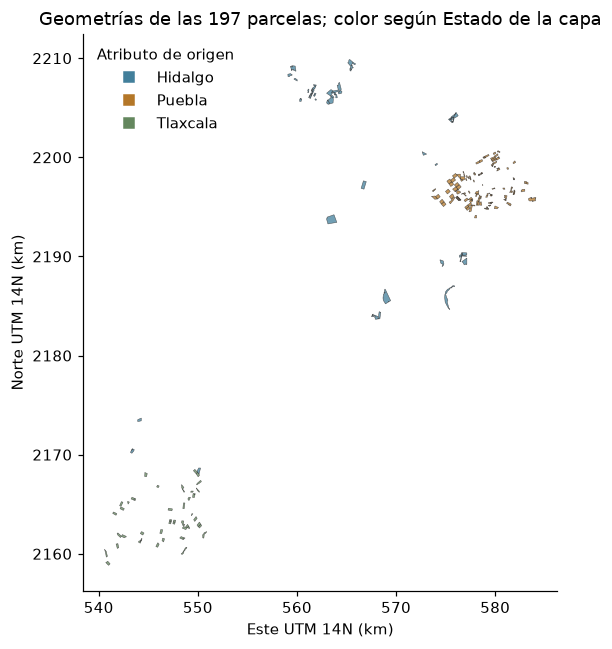

In [13]:
# Solo para representar las geometrías en metros: UTM 14N, EPSG:32614.
# No calcula extracciones ni áreas para el modelo.
convertir_mapa = Transformer.from_crs(crs_original, "EPSG:32614", always_xy=True)
geo_utm = [transform(convertir_mapa.transform, geom) for geom in geometrias]
geometria_por_id = dict(zip(atributos_geo["ID_POLIGONO"], geo_utm, strict=True))
colores_estado = {"Hidalgo": "#427f9b", "Puebla": "#b47728", "Tlaxcala": "#64875e"}
fig, ax = plt.subplots(figsize=(7.5, 6))
for fila in parcela.itertuples(index=False):
    geom = geometria_por_id[fila.ID_POLIGONO]
    partes = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]
    for parte in partes:
        xy = np.asarray(parte.exterior.coords) / 1000
        ax.add_patch(ParchePoligono(
            xy, closed=True, facecolor=colores_estado[fila.Estado],
            edgecolor="#333333", linewidth=0.35, alpha=0.75,
        ))
ax.autoscale_view()
ax.set_aspect("equal")
ax.set_xlabel("Este UTM 14N (km)")
ax.set_ylabel("Norte UTM 14N (km)")
ax.set_title("Geometrías de las 197 parcelas; color según Estado de la capa")
for estado, color in colores_estado.items():
    ax.plot([], [], marker="s", linestyle="", color=color, label=estado)
ax.legend(title="Atributo de origen", frameon=False)
fig.tight_layout()
plt.show()

**Respuesta.** La muestra se concentra en nueve municipios; Chignahuapan reúne
100 de las 197 parcelas, incluidas 71 de las 138 etiquetas y 29 de las 59 predicciones.

**Decisión derivada:** describir el modelo como calibrado en esta muestra de Valles
Altos, no como validado para toda Hidalgo, Tlaxcala y Puebla. Al evaluar modelos
revisaremos también resultados por región.

**Límite:** el mapa no demuestra autocorrelación, causalidad ni que el split oficial
sea aleatorio. Esas preguntas necesitan un análisis específico y, para el mecanismo
oficial de separación, información de los organizadores.

## 7. ¿Cómo se distribuye lo que queremos predecir?

**Qué comprobamos.** Escala, dispersión y precisión de las etiquetas visibles.
**Por qué importa.** Hay que distinguir un diagnóstico del objetivo de una explicación
causal o una regla que obligue a redondear futuras predicciones.

Utilizamos solo las 138 etiquetas disponibles. No imputamos los faltantes ni medimos
capacidad predictiva: una media o un histograma aquí son estadísticas descriptivas.

In [14]:
etiquetadas = parcela.loc[parcela["RENDIMIENTO_T_HA"].notna()].copy()
rendimiento = etiquetadas["RENDIMIENTO_T_HA"]
descripcion = rendimiento.describe().to_frame("rendimiento_t_ha")
descripcion.loc["valores_distintos"] = rendimiento.nunique()
display(descripcion)
display(etiquetadas.groupby("Estado")["RENDIMIENTO_T_HA"].agg(
    parcelas="count", media="mean", desviacion="std", minimo="min", maximo="max",
    valores_distintos="nunique",
).round(4))
es_multiplo_medio = np.isclose(
    rendimiento.to_numpy() * 2, np.rint(rendimiento.to_numpy() * 2),
    atol=1e-10, rtol=0,
)
n_redondeadas = int(es_multiplo_medio.sum())
print("Múltiplos de 0.5 t/ha, tolerancia 1e-10:", n_redondeadas,
      "de", len(rendimiento))

,rendimiento_t_ha
count,138.000000
mean,3.955362
std,0.851161
min,2.000000
25%,3.200000
50%,4.340000
75%,4.550000
max,5.590000
valores_distintos,67.000000


,parcelas,media,desviacion,minimo,maximo,valores_distintos
Estado,,,,,,
Hidalgo,36,3.7625,0.7776,2.00,4.87,21
Puebla,71,4.4773,0.5844,2.15,5.59,54
Tlaxcala,31,2.9839,0.3760,2.50,3.50,3


Múltiplos de 0.5 t/ha, tolerancia 1e-10: 45 de 138


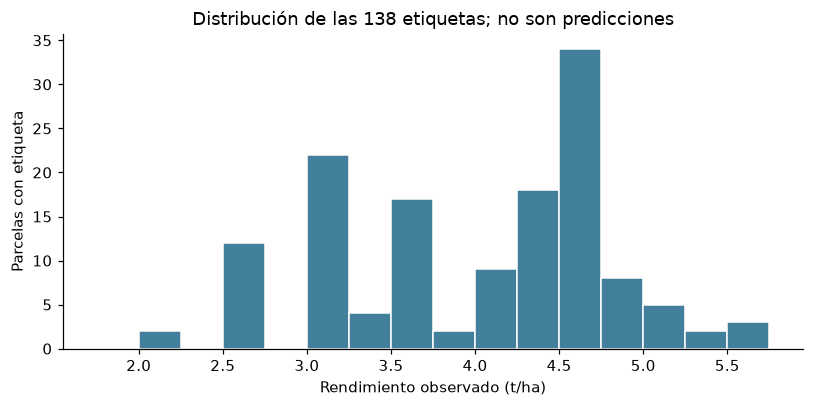

,t_ha,parcelas_Tlaxcala
0,2.5,9
1,3.0,14
2,3.5,8


In [15]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bordes = np.arange(1.75, 5.76, 0.25)
ax.hist(rendimiento, bins=bordes, color="#427f9b", edgecolor="white")
ax.set_xlabel("Rendimiento observado (t/ha)")
ax.set_ylabel("Parcelas con etiqueta")
ax.set_title("Distribución de las 138 etiquetas; no son predicciones")
fig.tight_layout()
plt.show()
valores_tlaxcala = etiquetadas.loc[
    etiquetadas["Estado"].eq("Tlaxcala"), "RENDIMIENTO_T_HA"
].value_counts().sort_index()
display(valores_tlaxcala.rename_axis("t_ha").reset_index(name="parcelas_Tlaxcala"))

**Respuesta.** El objetivo visible va de 2.00 a 5.59 t/ha. Parte de las etiquetas está
discretizada: 45 son múltiplos de 0.5 t/ha, y Tlaxcala tiene solo tres valores distintos.
Las regiones difieren tanto en nivel como en precisión aparente del registro.

**Límite:** esto es compatible con redondeo o procedimientos diferentes de captura,
pero no prueba cómo se midió el rendimiento, un piso de error irreducible o etiquetas
incorrectas. Tampoco convierte la regresión en clasificación ni justifica redondear
automáticamente las 59 estimaciones.

## 8. Faltantes y valores problemáticos: diagnóstico, no receta

**Qué comprobamos.** Disponibilidad de índices por sensor, nubosidad y LAI negativo.
**Por qué importa.** No todos los `NaN` significan nube ni todos los sensores entregan
las mismas variables. Primero distinguimos ausencia estructural de una medición faltante.

No recortamos LAI, no rellenamos `NaN` y no elegimos un umbral de nubosidad. Esas
decisiones corresponden a la preparación de variables y deberán justificarse por separado.

In [16]:
disponibilidad = []
for tabla in [basico, pro]:
    for sensor, grupo in tabla.groupby("sensor"):
        for indice in ["ndvi_promedio", "vi6t_promedio"]:
            existe = indice in grupo.columns
            presentes = int(grupo[indice].notna().sum()) if existe else 0
            disponibilidad.append({
                "sensor": sensor, "índice": indice, "columna_en_fuente": existe,
                "filas": len(grupo), "valores_presentes": presentes,
                "ausentes": len(grupo) - presentes,
            })
tabla_disponibilidad = pd.DataFrame(disponibilidad)
display(tabla_disponibilidad)
# En Básico, NDVI no es la medición disponible de Landsat; vi6t sí lo es.
assert basico.loc[basico["sensor"].eq("Landsat"), "ndvi_promedio"].isna().all()
assert basico.loc[basico["sensor"].eq("Sentinel-2"), "vi6t_promedio"].isna().all()

,sensor,índice,columna_en_fuente,filas,valores_presentes,ausentes
0,Landsat,ndvi_promedio,True,48626,0,48626
1,Landsat,vi6t_promedio,True,48626,31048,17578
2,Sentinel-2,ndvi_promedio,True,59040,44877,14163
3,Sentinel-2,vi6t_promedio,True,59040,0,59040
4,Planet,ndvi_promedio,True,47804,35747,12057
5,Planet,vi6t_promedio,False,47804,0,47804


In [17]:
calidad = []
for tabla in [basico, pro]:
    for sensor, grupo in tabla.groupby("sensor"):
        columna_disponible = "vi6t_promedio" if sensor == "Landsat" else "ndvi_promedio"
        faltante = grupo[columna_disponible].isna()
        nubes_100 = grupo["porcentaje_nubosidad"].eq(100)
        assert grupo["porcentaje_nubosidad"].dropna().between(0, 100).all()
        calidad.append({
            "sensor": sensor, "índice_de_control": columna_disponible,
            "faltantes": int(faltante.sum()),
            "faltantes_pct": float(100 * faltante.mean()),
            "filas_nubosidad_100": int(nubes_100.sum()),
            "nubosidad_desconocida": int(grupo["porcentaje_nubosidad"].isna().sum()),
            "faltantes_con_nube_desconocida": int((
                faltante & grupo["porcentaje_nubosidad"].isna()).sum()),
            "faltantes_con_nube_conocida_menor_100": int((
                faltante & grupo["porcentaje_nubosidad"].notna() & ~nubes_100).sum()),
        })
display(pd.DataFrame(calidad).round(2))
sentinel = basico.loc[basico["sensor"].eq("Sentinel-2")]
ciclo_sentinel = sentinel.loc[sentinel["FECHA"].between("2025-04-01", "2025-10-31")]
lai_observado = ciclo_sentinel["lai_promedio"].dropna()
print("LAI negativo en Sentinel-2, abril–octubre de 2025:",
      int(lai_observado.lt(0).sum()), "de", len(lai_observado),
      f"({100 * lai_observado.lt(0).mean():.2f} % de los valores presentes)")

,sensor,índice_de_control,faltantes,faltantes_pct,filas_nubosidad_100,nubosidad_desconocida,faltantes_con_nube_desconocida,faltantes_con_nube_conocida_menor_100
0,Landsat,vi6t_promedio,17578,36.15,14521,3056,3056,1
1,Sentinel-2,ndvi_promedio,14163,23.99,14163,0,0,0
2,Planet,ndvi_promedio,12057,25.22,12057,0,0,0


LAI negativo en Sentinel-2, abril–octubre de 2025: 1885 de 7352 (25.64 % de los valores presentes)


**Respuesta.** Landsat aporta `vi6t`, no NDVI. Las columnas comunes del CSV no implican
mediciones comunes entre sensores. La nubosidad debe leerse junto con disponibilidad
y procedencia, no usarse como explicación automática de toda ausencia. Una nubosidad
desconocida **no equivale a un cielo despejado**.

Un LAI negativo merece revisar definición y tratamiento; eliminarlo o conservarlo
cambia los resúmenes. **Esta auditoría señala el problema, pero no elige la receta**
según cuál produzca después la mejor puntuación.

## 9. Cierre: qué quedó demostrado

| Pregunta | Respuesta comprobable | Consecuencia para el recorrido |
|---|---|---|
| ¿Qué se predice? | Rendimiento continuo, t/ha, abril–octubre de 2025 | Regresión supervisada de una campaña |
| ¿Cuántas etiquetas hay? | 138 visibles; 59 intencionalmente ocultas | No imputar el objetivo faltante |
| ¿Cuál es la unidad? | Parcela; 155,470 filas satelitales no son nuevas etiquetas | Separar y evaluar por parcela |
| ¿Cómo se unen las fuentes? | Mismos 197 IDs; unión catálogo–capa uno a uno | Unir por ID, no por posición |
| ¿Qué territorio cubre? | Nueve municipios; 100 parcelas en Chignahuapan | Explicitar alcance y evaluar por región |
| ¿Es todo faltante equivalente? | Índices distintos por sensor y calidad heterogénea | Definir tratamientos por fuente |

**No concluimos** una receta óptima, efectos causales, el mecanismo oficial del split,
la precisión de un modelo ni capacidad para extrapolar a otros ciclos o regiones.

La siguiente celda deja un resumen verificable y comprueba que el ZIP no cambió.
No guarda datos ni predicciones en disco.

In [18]:
hash_final = hashlib.sha256(ruta_dataset.read_bytes()).hexdigest()
assert hash_final == hash_inicial == SHA256_DATASET
resumen_auditoria = {
    "notebook": "01_auditoria_y_unidad_parcela",
    "fecha_adaptacion": "2026-10-07",
    "fecha_ejecucion_utc": FECHA_EJECUCION_UTC,
    "sha256_dataset": hash_final,
    "bytes_dataset": int(ruta_dataset.stat().st_size),
    "parcelas": int(n_parcelas), "etiquetas": int(n_etiquetas),
    "por_predecir": int(n_ocultas),
    "filas_basico": int(len(basico)), "filas_pro": int(len(pro)),
    "filas_satelitales": int(len(basico) + len(pro)),
    "estados": int(parcela["Estado"].nunique()),
    "municipios": int(len(tabla_municipios)),
    "chignahuapan_etiquetas": int(concentracion["ENTRENAMIENTO"]),
    "chignahuapan_ocultas": int(concentracion["PREDICCION"]),
    "rendimiento_minimo_t_ha": float(rendimiento.min()),
    "rendimiento_maximo_t_ha": float(rendimiento.max()),
    "multiplos_05_t_ha": n_redondeadas,
    "diferencia_area_declarada_max_ha": float(diferencia_area_declarada),
    "geometrias_validas": int(sum(geom.is_valid for geom in geometrias)),
    "objetivos_imputados": 0,
    "modelos_entrenados": 0, "predicciones_finales_generadas": 0,
    "extracciones_raster": 0, "archivo_original_inalterado": True,
}
zip_fuente.close()
print(json.dumps(resumen_auditoria, ensure_ascii=False, indent=2))
print("RESUMEN_AUDITORIA_JSON=" + json.dumps(
    resumen_auditoria, sort_keys=True, ensure_ascii=False))

{
  "notebook": "01_auditoria_y_unidad_parcela",
  "fecha_adaptacion": "2026-10-07",
  "fecha_ejecucion_utc": "2026-10-07T18:42:37.295074+00:00",
  "sha256_dataset": "d74dbaba1764e026da8ce38f7f3476f80523f479a6c141827887e09326061bb5",
  "bytes_dataset": 29687194,
  "parcelas": 197,
  "etiquetas": 138,
  "por_predecir": 59,
  "filas_basico": 107666,
  "filas_pro": 47804,
  "filas_satelitales": 155470,
  "estados": 3,
  "municipios": 9,
  "chignahuapan_etiquetas": 71,
  "chignahuapan_ocultas": 29,
  "rendimiento_minimo_t_ha": 2.0,
  "rendimiento_maximo_t_ha": 5.59,
  "multiplos_05_t_ha": 45,
  "diferencia_area_declarada_max_ha": 0.0,
  "geometrias_validas": 197,
  "objetivos_imputados": 0,
  "modelos_entrenados": 0,
  "predicciones_finales_generadas": 0,
  "extracciones_raster": 0,
  "archivo_original_inalterado": true
}
RESUMEN_AUDITORIA_JSON={"archivo_original_inalterado": true, "bytes_dataset": 29687194, "chignahuapan_etiquetas": 71, "chignahuapan_ocultas": 29, "diferencia_area_declara

## 10. La siguiente pregunta

**¿Cómo convertir las fuentes de una parcela en una fila de variables sin desplazarla,
cambiar sus unidades o confundir píxeles extremos con promedios?**

El cuaderno 02 retomará **preparar los datos**, porque esta auditoría identificó qué
debe controlarse antes de modelar: geometría y proyección, mallas y NoData,
intersecciones y pesos, ventanas temporales y significado de los resúmenes.
Las recetas se contrastarán con controles independientes; su utilidad predictiva
se estudiará después, mediante comparaciones fuera de muestra.

### Conceptos breves

- **Etiqueta:** rendimiento conocido que queremos aprender a estimar.
- **Unidad de observación:** la parcela cuyo rendimiento constituye un caso del problema.
- **Ausencia estructural:** variable que una fuente no entrega; no es una medición nublada.
- **CRS:** referencia espacial que da significado a las coordenadas; grados no son metros.
- **Integridad:** identidad del archivo. No acredita representatividad ni ausencia de sesgos.

### Fuentes y referencias — APA 7

*Descripción general del conjunto de datos*. (s. f.). [Documento proporcionado con el
dataset del Reto AgroCebada 2026]. Archivo `Descripcion_general_variables_DataSet.docx`,
sección 1, dentro de `DataSet.zip`. Es la fuente de la campaña objetivo y de la
descripción de los sensores; los conteos se recalculan aquí desde los datos.

*DataSet.zip*. (s. f.). [Paquete de datos proporcionado para el Reto AgroCebada 2026].
Identificador SHA-256 impreso en las secciones 2 y 9.

Para revisar las herramientas de lectura y transformación, sin convertirlas en
respaldo de las conclusiones agronómicas:

pandas development team. (s. f.). *pandas documentation*. https://pandas.pydata.org/docs/

PyShp contributors. (s. f.). *PyShp: Python Shapefile Library*.
https://github.com/GeospatialPython/pyshp

pyproj contributors. (s. f.). *pyproj documentation*. https://pyproj4.github.io/pyproj/stable/